# CsI(Tl)–SiPM：Geant4 波形参数再校准

记录日期：2026-10-29。目标是在真实 Geant4 核衰变、光学输运和原生 SiPM 数字化基础上，
使模拟的平均形状、峰值时间、积分比、基线与起伏统计接近实测。随机单条波形的细峰不要求逐点相同。

装置已知为 10×10×10 mm³ CsI(Tl)、PTFE 侧面包裹、前面 5 µm Mylar、S13361-3050 阵列多个单元求和、无前放。
精确求和电路、源距、历史输入范围和温度仍不全。²⁴¹Am 包含 α 和 γ，源名不能代替实测逐事件粒子标签。

本笔记保留拟合方法、参数、实际执行输出、图与未通过的项目。旧阶段结果不覆盖。

In [1]:
from pathlib import Path
import json, sys
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'simulation/main.cc').exists())
OLD = PROJECT / 'simulation/results/signal_fluctuations_20261028'
NEW = PROJECT / 'simulation/results/waveform_refit_20261029'
def read(path):
    return json.loads(Path(path).read_text())
print('Project:', PROJECT)
print('Notebook Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Numerical G4/PyROOT scripts use /usr/bin/python3; this notebook uses the existing Jupyter environment.')

Project: /media/sf_works/SiPM
Notebook Python: 3.13.5
NumPy: 2.5.4
Numerical G4/PyROOT scripts use /usr/bin/python3; this notebook uses the existing Jupyter environment.


## 1. 上一版的起点与剩余差距

上一版按 run 训练信号相关随机残差；RC 为 105 ns。训练仅用 run 3 / 12 前 60% 原始序号区间内
的 2450 / 1547 条冻结合格波形。之后用新随机种子完成 4000 / 24000 个 Co / Am 衰变。
下表按旧结果重新读取，不能把归一化平均形状误差小直接等同于全部响应一致。

In [2]:
old = read(OLD / 'independent/validation.json')
lines = ['|源 / 检查组|平均形状 NRMSE|F50 偏差|F102 偏差|F202 偏差|', '|---|---:|---:|---:|---:|']
for source, run in [('Co60', 3), ('Am241', 12)]:
    row = old['sources'][source]['comparisons'][f'run{run}_last20']
    lines.append(f"|{source} / 后20%|{100*row['shape_nrmse']:.2f}%|" + '|'.join(f'{100*x:+.2f}%' for x in row['relative']) + '|')
display(Markdown('\n'.join(lines)))
extra = read(OLD / 'waveform_feature_checks.json')['variants']['independent']['sources']
for source, run in [('Co60', 3), ('Am241', 12)]:
    print(source)
    for key in ('tpeak_minus_t10_ns', 'short_long_ratio', 'baseline_RMS_ADC'):
        row = extra[source][f'run{run}_last20'][key]
        print(' ', key, 'MC/data medians:', round(row['MC_q25_median_q75'][1], 4), round(row['data_q25_median_q75'][1], 4), 'KS:', round(row['KS'], 3))

|源 / 检查组|平均形状 NRMSE|F50 偏差|F102 偏差|F202 偏差|
|---|---:|---:|---:|---:|
|Co60 / 后20%|2.17%|+0.08%|-2.14%|+3.57%|
|Am241 / 后20%|1.08%|+4.20%|+3.49%|-1.07%|

Co60
  tpeak_minus_t10_ns MC/data medians: 232.4624 197.6287 KS: 0.379
  short_long_ratio MC/data medians: 0.4454 0.4653 KS: 0.618
  baseline_RMS_ADC MC/data medians: 3.3737 3.3174 KS: 0.151
Am241
  tpeak_minus_t10_ns MC/data medians: 271.6489 289.8163 KS: 0.105
  short_long_ratio MC/data medians: 0.3234 0.325 KS: 0.171
  baseline_RMS_ADC MC/data medians: 3.3831 5.6774 KS: 0.928


## 2. 本轮参数搜索与验证规则

1. 先用冻结训练波形重估发光时间、快慢份额和共同读出 RC；加入上升段与积分比约束。
2. 快速期望模型只提出参数；候选必须送回完整 Geant4 产生光子，再经原生数字化验证。
3. 信号内残差只在训练段重估；基线校准仅使用前触发样本，单独标注采集条件。
4. run 3/12 中段、后段排除在本轮信号拟合之外；另设 run 18 前段训练分支，检查其中段/后段。各检查段以前已探索，不称为盲验证。
5. 展示固定 Q 排位的未缩放 ADC 示例，同时保留峰值/积分比/起伏分布、电荷谱以及失败项。

这些参数是当前装置假设下的条件估计，不能由拟合吻合反推唯一的本征材料常数或真实电路。

### 两类平均形状模型的搜索

先检验共享发光时间的模型，再允许电子与 α 沉积分开使用时间常数；读出参数仍共用。
第二类模型还允许工程已有的快路径份额变化。目标包含平均曲线、峰值时间、上升到 50% / 90% 的时间和积分比。
目标函数的尺度是描述性拟合权重，不是独立测量误差或 χ² 概率。

快速模型使用上一轮原生 MC 与解析均值的平滑差异来提出候选；这项差异不会写入原生波形。
完整 Geant4 只接收时间常数、份额、RC、光产额等数值参数。边界附近的参数及有限窗口内未约束的长时间常数均需保留说明。

In [3]:
for relative in ['shape_fit.json', 'parallel_shape/shape_fit.json']:
    path = NEW / relative
    if not path.exists():
        print(relative, '尚未完成')
        continue
    fit = read(path)
    best = fit['selected']['best']
    display(Markdown('**' + relative + '**'))
    print('Selected parameters:', json.dumps(best['parameters'], indent=2))
    print('Descriptive objective:', best['objective'])
    for source, row in best['metrics'].items():
        print(source, 'proposal mean NRMSE:', round(100*row['mean_nrmse'], 3), '%')
    print('这些是候选拟合值，实际吻合程度以下面的原生输出为准。')

**shape_fit.json**

Selected parameters: {
  "electron_tau_ns": [
    150.00000000000009,
    767.7325839334723
  ],
  "alpha_tau_ns": [
    842.5382636016094,
    7999.999924512168
  ],
  "lowpass_ns": 119.26438231202134,
  "electron_fast_fraction": 0.16377293540935234,
  "alpha_fast_fraction": 0.5272787372171635
}
Descriptive objective: 12.123900172196219
Co60 proposal mean NRMSE: 1.132 %
Am241 proposal mean NRMSE: 0.902 %
这些是候选拟合值，实际吻合程度以下面的原生输出为准。


**parallel_shape/shape_fit.json**

Selected parameters: {
  "electron_tau_ns": [
    93.72033919074961,
    700.0000000737917
  ],
  "alpha_tau_ns": [
    791.3891521932289,
    8438.62820399502
  ],
  "lowpass_ns": 126.81563167725534,
  "electron_fast_fraction": 0.11952437268968853,
  "alpha_fast_fraction": 0.47101027493882375,
  "prompt_charge_fraction": 7.297304900925533e-12
}
Descriptive objective: 8.774129351389671
Co60 proposal mean NRMSE: 0.899 %
Am241 proposal mean NRMSE: 1.011 %
这些是候选拟合值，实际吻合程度以下面的原生输出为准。


### 基线与信号内起伏分开处理

基线状态只使用每条波形最前面的 128 个采样点。保留原平稳 FIR，允许事件间噪声方差具有均值为 1 的
对数正态乘子，以及基线电平变化。先检验单一状态；由于 Am 训练段包含少量基线偏移较大的记录，
再比较 1 / 2 个联合高斯状态，并用 BIC 选择，要求每个状态至少有 20 个有效样本。
状态同时描述基线电平与对数方差的相关性；有限 128 点估计噪声通过 FIR 协方差矩近似扣除。
这是一种采集状态描述，不是已确认的电路原因。关闭新增参数时，旧随机数和输出保持不变。

训练配置只用训练前触发区。若后续给出后段“前触发条件化”的配置，它明确使用了该段的前触发统计，
属于给定采集状态的比较，不能写成仅从训练段预测出了后段漂移；脉冲部分仍不用于这项基线估计。

In [4]:
path = NEW / 'baseline_states.json'
if path.exists():
    states = read(path)['states']
    rows = ['|数据段|基线 mV|噪声 RMS mV|事件方差 CV|实测基线 RMS 中位 ADC|', '|---|---:|---:|---:|---:|']
    for group, row in states.items():
        rows.append(f"|{group}|{row['baseline_mV']:.4f}|{row['noise_rms_mV']:.5f}|{row['event_variance_cv']:.3f}|{row['measured_RMS_ADC_quantiles'][1]:.3f}|")
    display(Markdown('\n'.join(rows)))
else:
    print('基线统计尚未完成。')

|数据段|基线 mV|噪声 RMS mV|事件方差 CV|实测基线 RMS 中位 ADC|
|---|---:|---:|---:|---:|
|run3_first60|92.7041|0.10662|0.202|3.353|
|run3_middle20|92.6924|0.10622|0.236|3.331|
|run3_last20|92.6982|0.10575|0.204|3.317|
|run12_first60|92.8892|0.10550|0.487|3.167|
|run12_middle20|93.3089|0.15720|0.742|4.415|
|run12_last20|93.6842|0.18596|0.466|5.677|

In [5]:
path = NEW / 'baseline_mixture_fit.json'
if path.exists():
    mixtures = read(path)
    rows = ['|数据段|选中状态数|状态权重|说明|', '|---|---:|---|---|']
    for group, row in mixtures['groups'].items():
        weights = ', '.join(f'{100*w:.1f}%' for w in row['selected']['weights'])
        role = '训练前触发区' if group.endswith('first60') else '本段前触发条件，非预测'
        rows.append(f"|{group}|{row['selected']['components']}|{weights}|{role}|")
    display(Markdown('\n'.join(rows)))
else:
    print('联合状态检查尚未完成。')

|数据段|选中状态数|状态权重|说明|
|---|---:|---|---|
|run3_first60|2|29.4%, 70.6%|训练前触发区|
|run3_middle20|2|33.2%, 66.8%|本段前触发条件，非预测|
|run3_last20|2|41.3%, 58.7%|本段前触发条件，非预测|
|run12_first60|2|95.2%, 4.8%|训练前触发区|
|run12_middle20|2|41.6%, 58.4%|本段前触发条件，非预测|
|run12_last20|1|100.0%|本段前触发条件，非预测|

## 3. 冻结参数后的完整 Geant4 结果

本轮完成两批完整输运：候选阶段 Co 4000 + Am 24000；冻结最终参数后另用新种子 Co 4000（291029503）+ Am 24000（291029512）。合计新增 **56000 个完整母衰变历史**。下表使用最后一批。其共同 Q 区间内合格 MC 仅为 Co **129**、Am **172** 条，不能把 28000 个母衰变全当作有效波形。数字化重放复用这些历史，不增加独立 MC 数。

run 3 / 12 的训练波形数为 2450 / 1547；中段为 853 / 460；后段为 826 / 407。run 18 另用冻结前段 3000 条训练读出残差，冻结中段、后段各 3000 条作检查。run 18 全部合格前/中/后段分别有 65034 / 21628 / 21521 条；本轮该分支没有宣称使用全部事件。

### 指标定义和比较范围

共同 Q 区间为 **201824.1125–418733.2 ADC·sample**；原冻结实测 ID 不变。MC 重新执行相同的质量、幅度≥200 ADC、Q 区间与触发前窗口条件。平均形状逐条扣基线、按 t10 对齐后用 [−40,3000) ns 积分归一化。NRMSE 是 [−100,3500] ns 内平均曲线差的 RMS 除以实测平均曲线最大值，**不是逐点相对误差，也不是幅度误差**。

配置内的 acquisition.amplitude_threshold_adc 是软件触发代理，不是硬件触发仿真。run18 分支继承 Am 配置的160 ADC代理；本文比较统一再要求幅度≥200 ADC，不据此还原该次采集的硬件阈值或低于阈值的探测效率。

F50 / F102 / F202：减去对应宽度的中心滑动平均，以 [500,2500) ns 信号残差方差减去 [−600,−200) ns 前触发残差方差，再除以信号区均值，单位 ADC。它是依赖滤波器的经验量，不能直接解释为增益或光电子数。表中偏差为 MC/实测−1。

下表使用前段训练状态，未使用后段的基线或脉冲重新拟合。平均形状在 Co 上明显改善，Am 从上一版约 1.08% 变为约 1.18%，**不能写成每项都改善**。

|后段检查|平均 NRMSE|F50|F102|F202|Q 谱 KS|
|---|---|---|---|---|---|
|Co60 / 上一版|2.167%|+0.08%|-2.14%|+3.57%|0.189|
|Co60 / 本轮冻结|1.026%|+1.75%|+0.85%|+4.11%|0.257|
|Am241 / 上一版|1.077%|+4.20%|+3.49%|-1.07%|0.190|
|Am241 / 本轮冻结|1.179%|+2.70%|+2.28%|-0.20%|0.223|

|源|滤波宽度 ns|后段偏差|条件 95% 区间|
|---|---|---|---|
|Co60|50|+1.75%|[-2.84, 6.47]%|
|Co60|102|+0.85%|[-2.60, 4.92]%|
|Co60|202|+4.11%|[0.11, 8.72]%|
|Am241|50|+2.70%|[-0.31, 5.65]%|
|Am241|102|+2.28%|[-1.06, 5.61]%|
|Am241|202|-0.20%|[-3.93, 3.75]%|

区间来自 512 次母衰变重采样与实测原始序号 64 条块重采样；参数、模型选择和前触发校准均固定，未计入拟合不确定度，未作多重比较修正。Co F202 的区间仍略高于零；小偏差不能自动称为统计等效。新随机种子检验的是 MC 重复性；既有中/后段在以前阶段已看过，不是新的盲实验数据。

### 峰值时间、积分比和后段基线

|源|特征|MC 中位数|实测中位数|MC−实测的条件95%区间|
|---|---|---|---|---|
|Co60|峰值−t10 / ns|191.01|197.63|[-17.49, -1.40]|
|Co60|短长积分比|0.4618|0.4653|[-0.0058, -0.0004]|
|Am241|峰值−t10 / ns|316.42|289.82|[0.91, 39.65]|
|Am241|短长积分比|0.3251|0.3250|[-0.0037, 0.0033]|

Co 峰值时间较上一版更接近，但仍略早；Am 的峰值仍偏晚约 27 ns。因此本轮只达到主要平均形状和起伏均值的近似匹配，尚未通过所有特征分布的一致性检验。

|源|读出状态|MC基线RMS/ADC|实测/ADC|RMS KS|平均NRMSE|F50|F102|F202|
|---|---|---|---|---|---|---|---|---|
|Co60|前段训练状态|3.377|3.317|0.100|1.026%|+1.75%|+0.85%|+4.11%|
|Co60|后段前触发条件化|3.368|3.317|0.072|1.025%|+1.57%|+0.79%|+4.05%|
|Am241|前段训练状态|3.215|5.677|0.883|1.179%|+2.70%|+2.28%|-0.20%|
|Am241|后段前触发条件化|5.620|5.677|0.081|1.143%|+3.10%|+2.29%|-0.13%|

后段条件化只读取该段最前 128 个样本的统计，保持发光、SiPM、信号残差不变。它能复现 Am 后段基线的主要变化，但用到了该段数据，不能作为前段参数预测后段基线的证据。模型允许事件间电平、方差及其相关性变化，未推断变化的电路原因。

### run 18：同一物理模型，单独训练采集状态

直接把 run 12 状态用于 run 18 前段时，F50 偏差仍为 **+64.82%**。该迁移失败保留。另用 run 18 前段 3000 条重新估计信号残差强度、相关频谱与方差分散，没有更改几何、闪烁或 SiPM 参数。下面是这个**独立校准分支**，不是宣称 run 12 参数已经迁移成功。

|run18检查 / 前段状态|平均NRMSE|F50|F102|F202|Q谱KS|
|---|---|---|---|---|---|
|run18_middle20|1.053%|-1.61%|-1.58%|-3.03%|0.515|
|run18_last20|0.961%|-1.62%|-1.49%|-3.21%|0.536|

run 18 后段 F50/F102/F202 的条件95%区间分别为 [-5.39, 2.52]%、[-5.64, 2.48]%、[-7.37, 0.91]%。run 18 基线 RMS 中位数 MC/实测为 4.940/4.950 ADC。但 Q 谱差异很大，不能把它当作绝对能谱或所有脉冲幅度均已复现。

## 4. 当前可复现的参数

|参数|值|
|---|---|
|电子/γ沉积时间常数|93.720, 700.000 ns|
|电子快份额|0.130398|
|α沉积时间常数|791.389, 8438.628 ns|
|α快份额|0.484029|
|共同被动 RC|126.816 ns|
|候选快路径电荷份额|7.3e-12（实际为零）|
|有效光产额|17590.196 photons/MeV|
|α相对产额|0.971946|
|固定假设|PDE 0.30、增益1.7×10⁶、50 Ω、恢复29 ns、16单元求和、输入500 mV|

|采集run|信号残差方差系数 κ / ADC|事件方差CV|FIR抽头数（2ns采样）|
|---|---|---|---|
|3|0.261347|0.198662|1025|
|12|1.522652|0.090485|1025|
|18|0.756696|0.173554|1025|

信号残差模型为 nᵢ=√(κ·max(Sᵢ,0)·V)·(h∗z)ᵢ，Sᵢ 是原生无噪声信号的 ADC 值，∑h²=1，V 是均值1的对数正态方差乘子。1025个抽头由训练频谱与100 ns相关项、白项的正组合生成；并非1025个自由参数逐点追踪实测波形。完整系数与前触发状态保存在配置 JSON 中。

电子慢时间 700 ns 位于搜索下界；α慢时间约 8.44 µs 长于本次形状检查窗。它们与 RC、份额、有限积分窗及光产额相互关联，当前是装置假设下的有效拟合值，**不能报告为该 CsI(Tl) 晶体本征时间常数或已测 α 淬灭比**。光产额调整仅保持时间参数改变后的期望3µs积分，没有按事件缩放模拟。快路径份额趋于零，不支持宣称需要额外快路径。源距仍沿用候选 Co 1 mm（假设0.25 mm Al出口片）/ Am 30 mm，未恢复真实装置历史。配置中的 evidence 保留历次假设，当前数值应以本表、status 与本次记录为准。

### 仍未解决、会限制文章结论的部分

Q 谱 KS 在 Co/run12 后段为约 0.257/0.223，run18 约 0.536；Am MC 在共同Q高端的事件支持不足，等Q箱比较只能使用满足数据≥20、MC≥10的箱。不能用等Q箱权重图代替未加权能谱检验。峰值时间和部分分布仍偏离。读出状态单独校准是一种经验响应补全，不构成唯一物理机理；没有补测单光电子响应、完整接线、温度、源封装与距离，因此只支持限定Q区间内的条件波形校准。

## 5. 图与未缩放单条波形

以下依次显示平均形状与起伏均值、特征分布、单条ADC、未加权Q谱和run18分支。单条示例固定取实测Q的25%/75%排位（run18取50%），选择最近Q的MC事件，仅扣基线并按t10对齐，没有按幅度或形状挑选。图例中的 pretrigger-conditioned 表示使用了该段前触发统计。实验和模拟是独立随机事件，不要求随机细峰逐点重合。

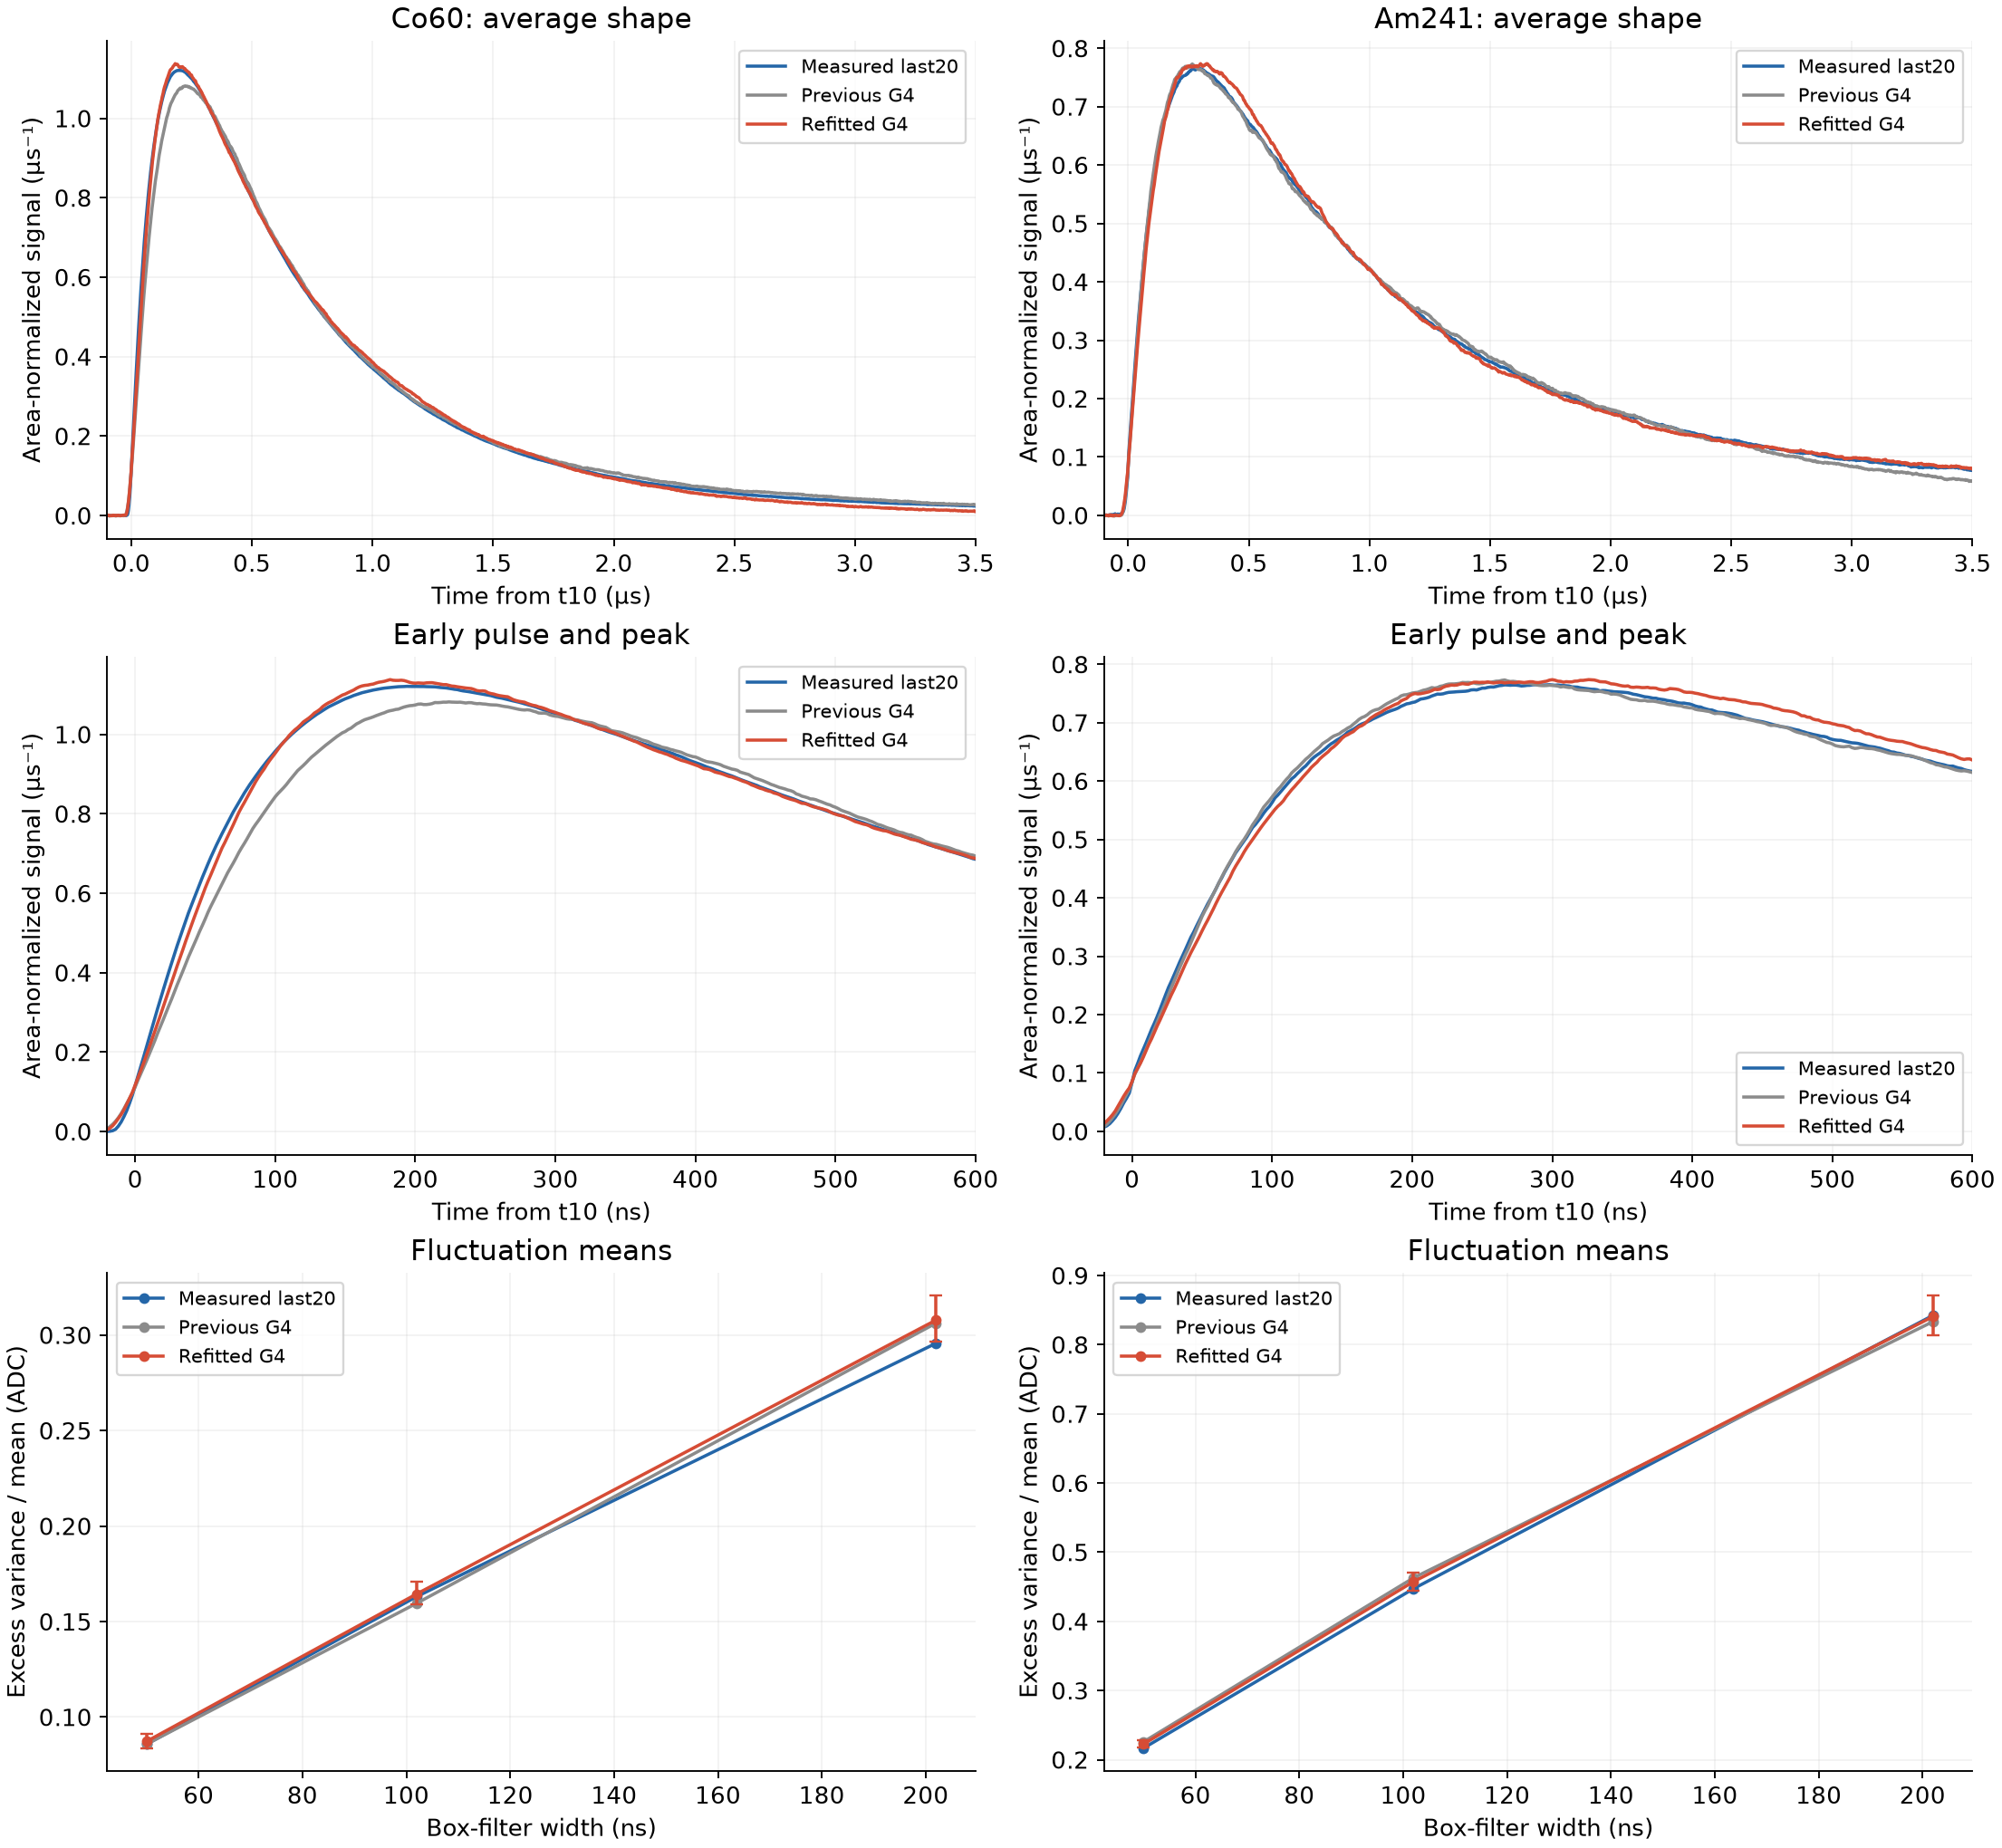

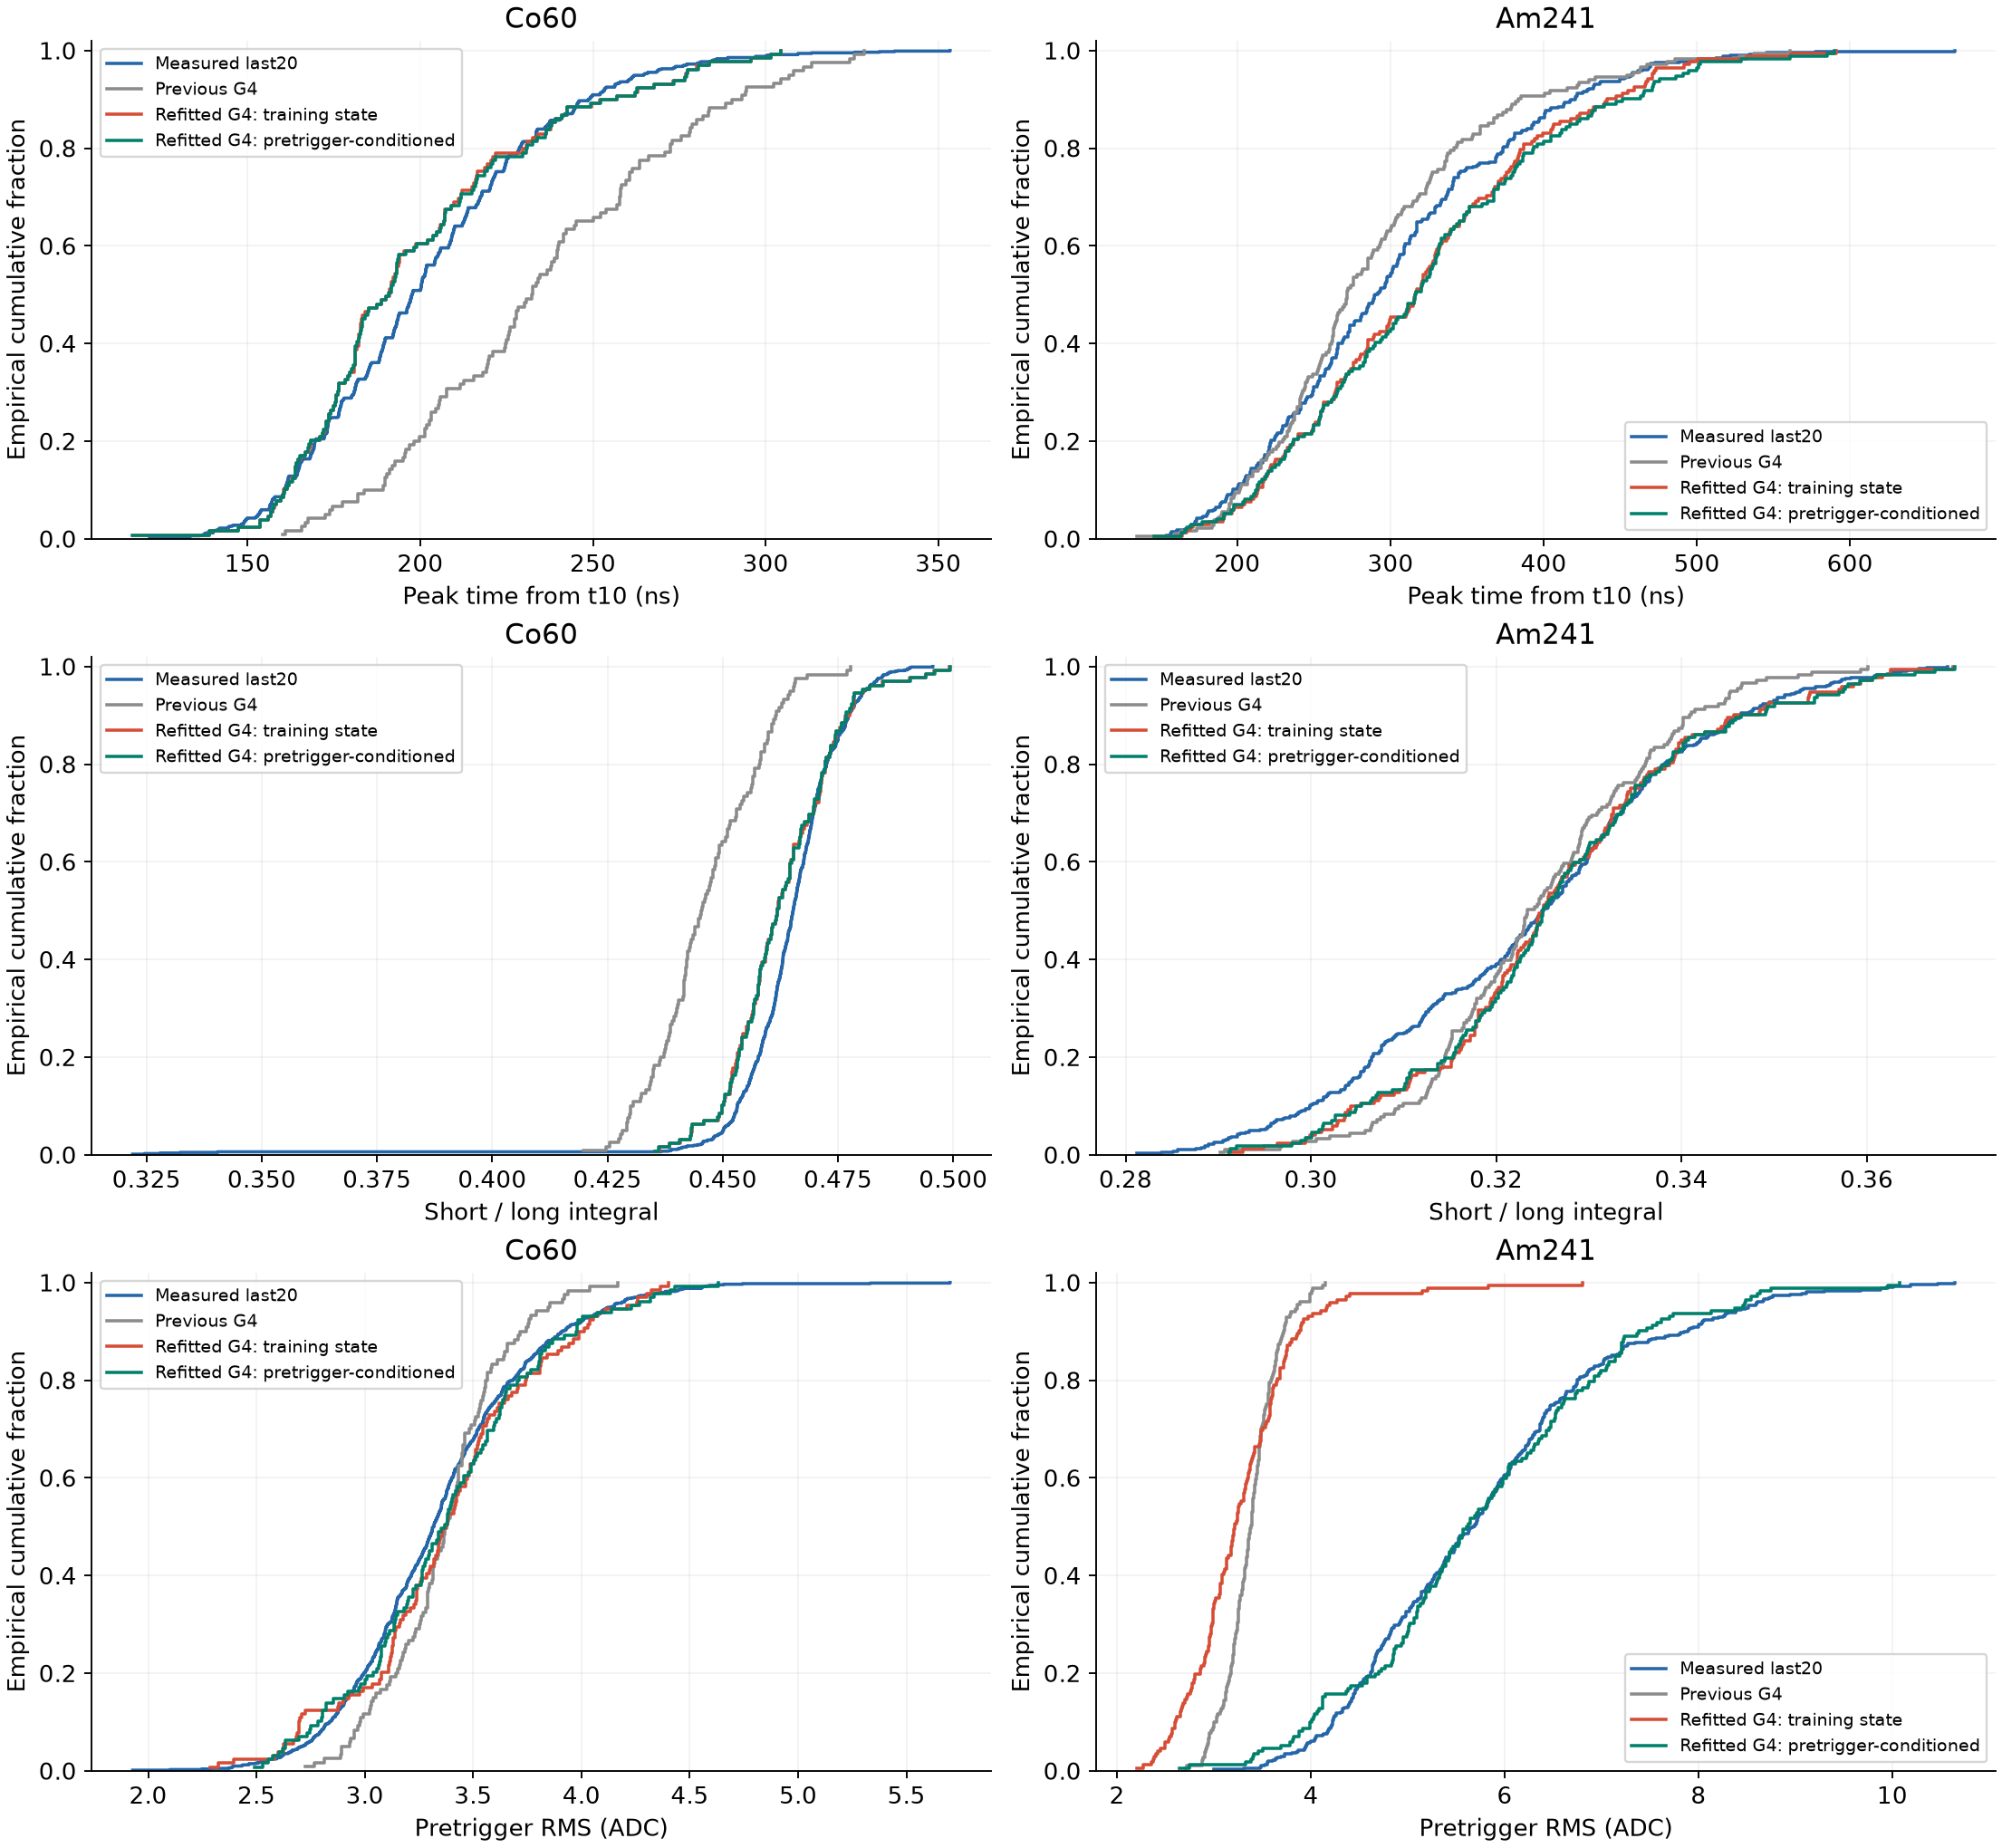

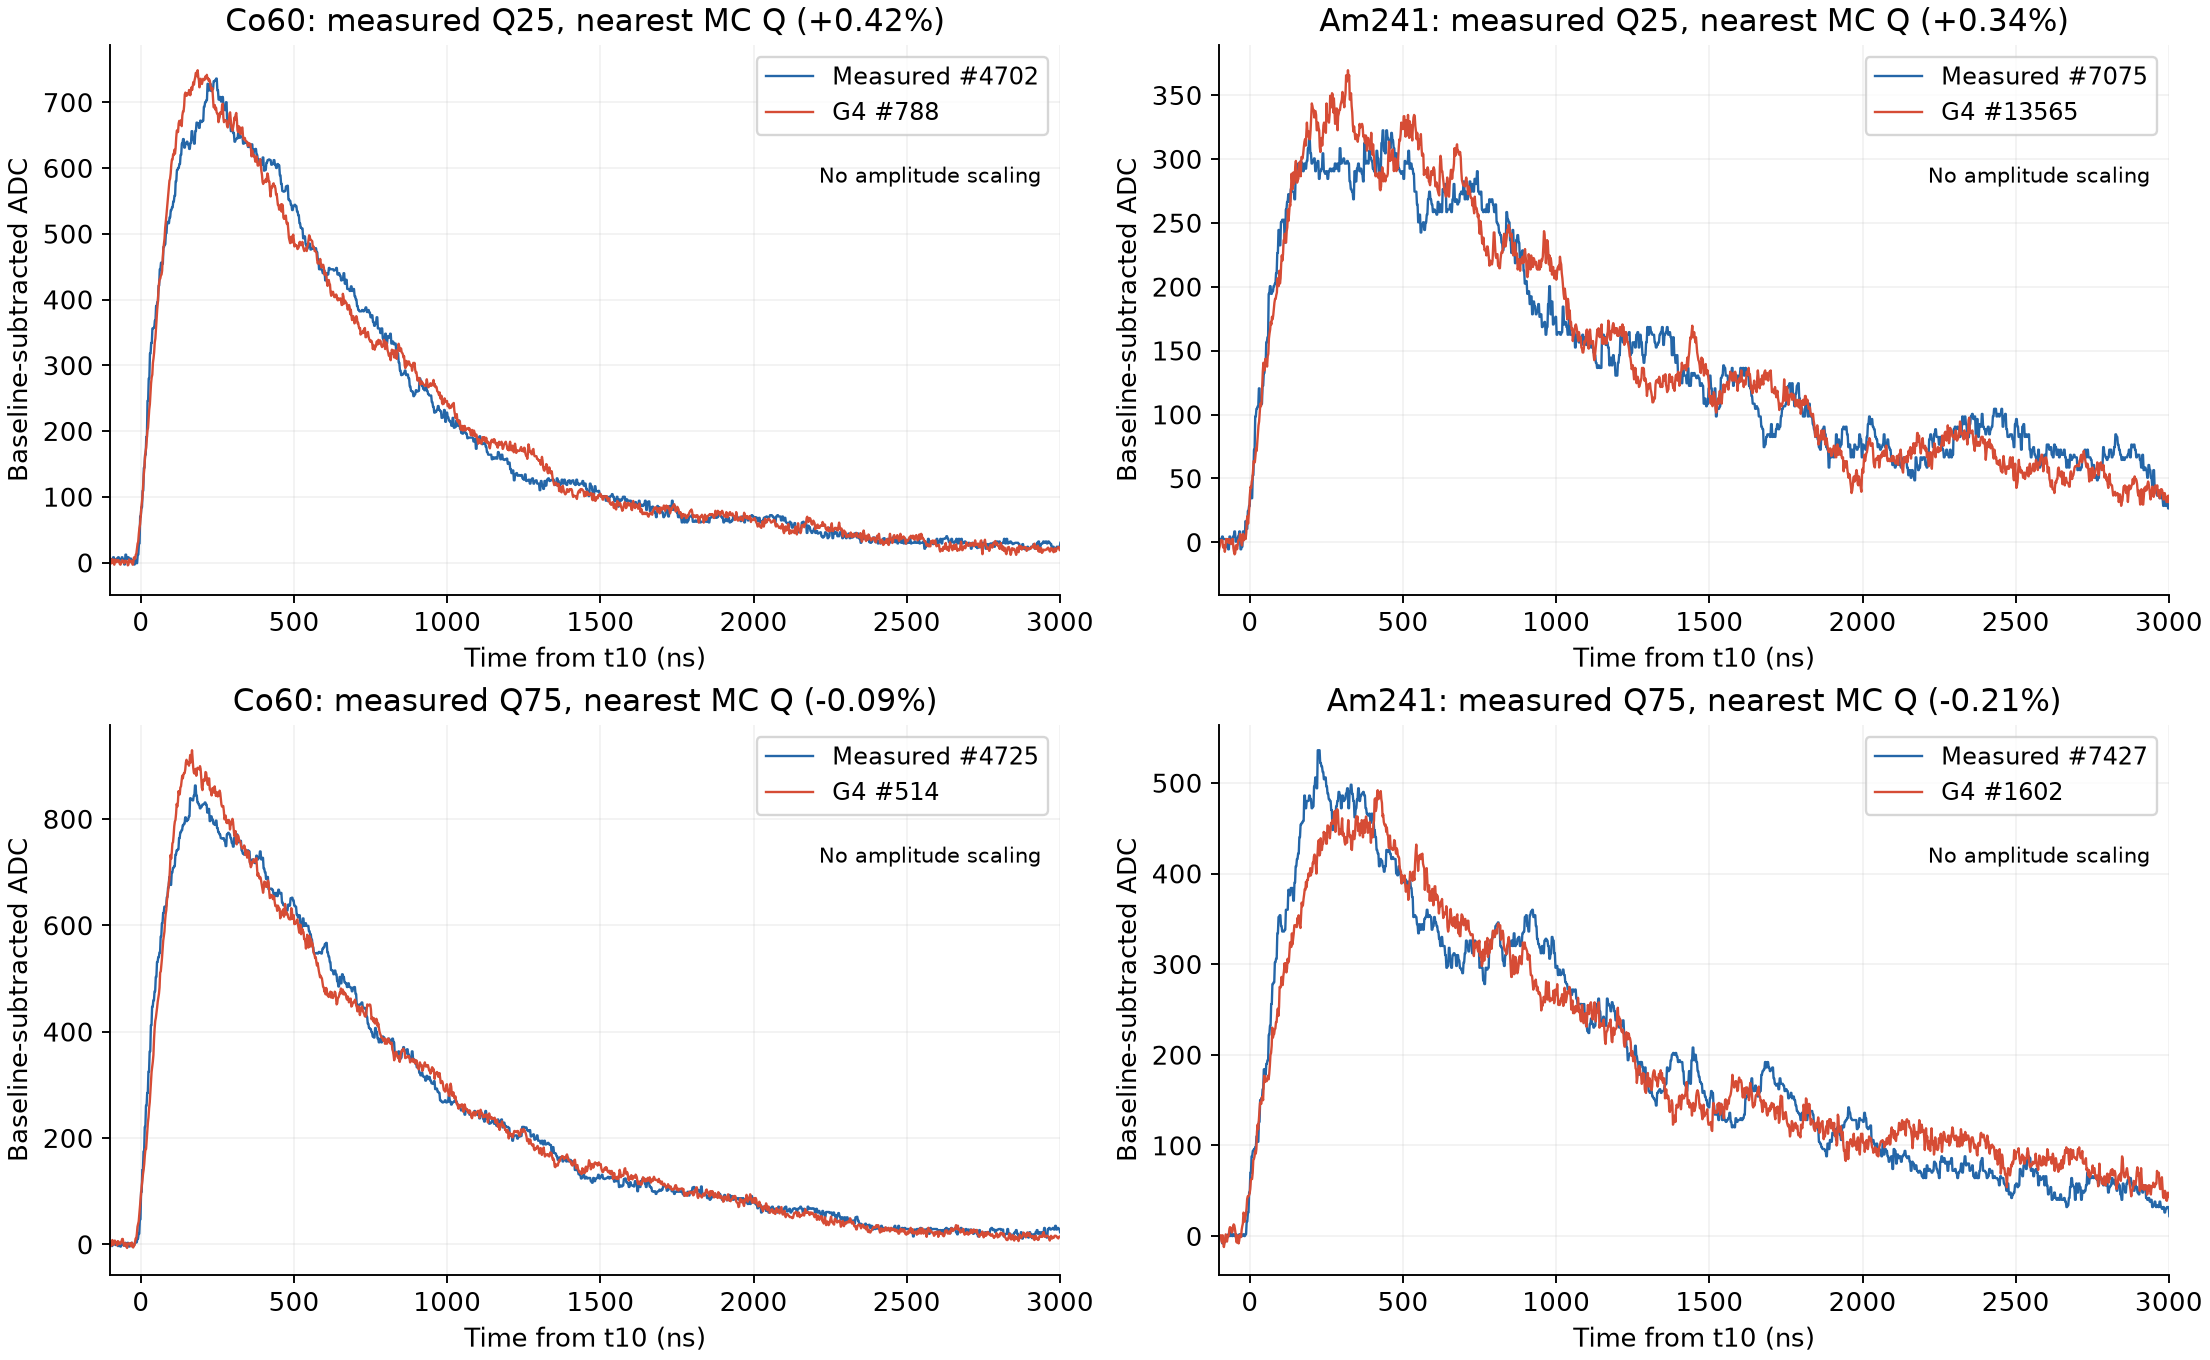

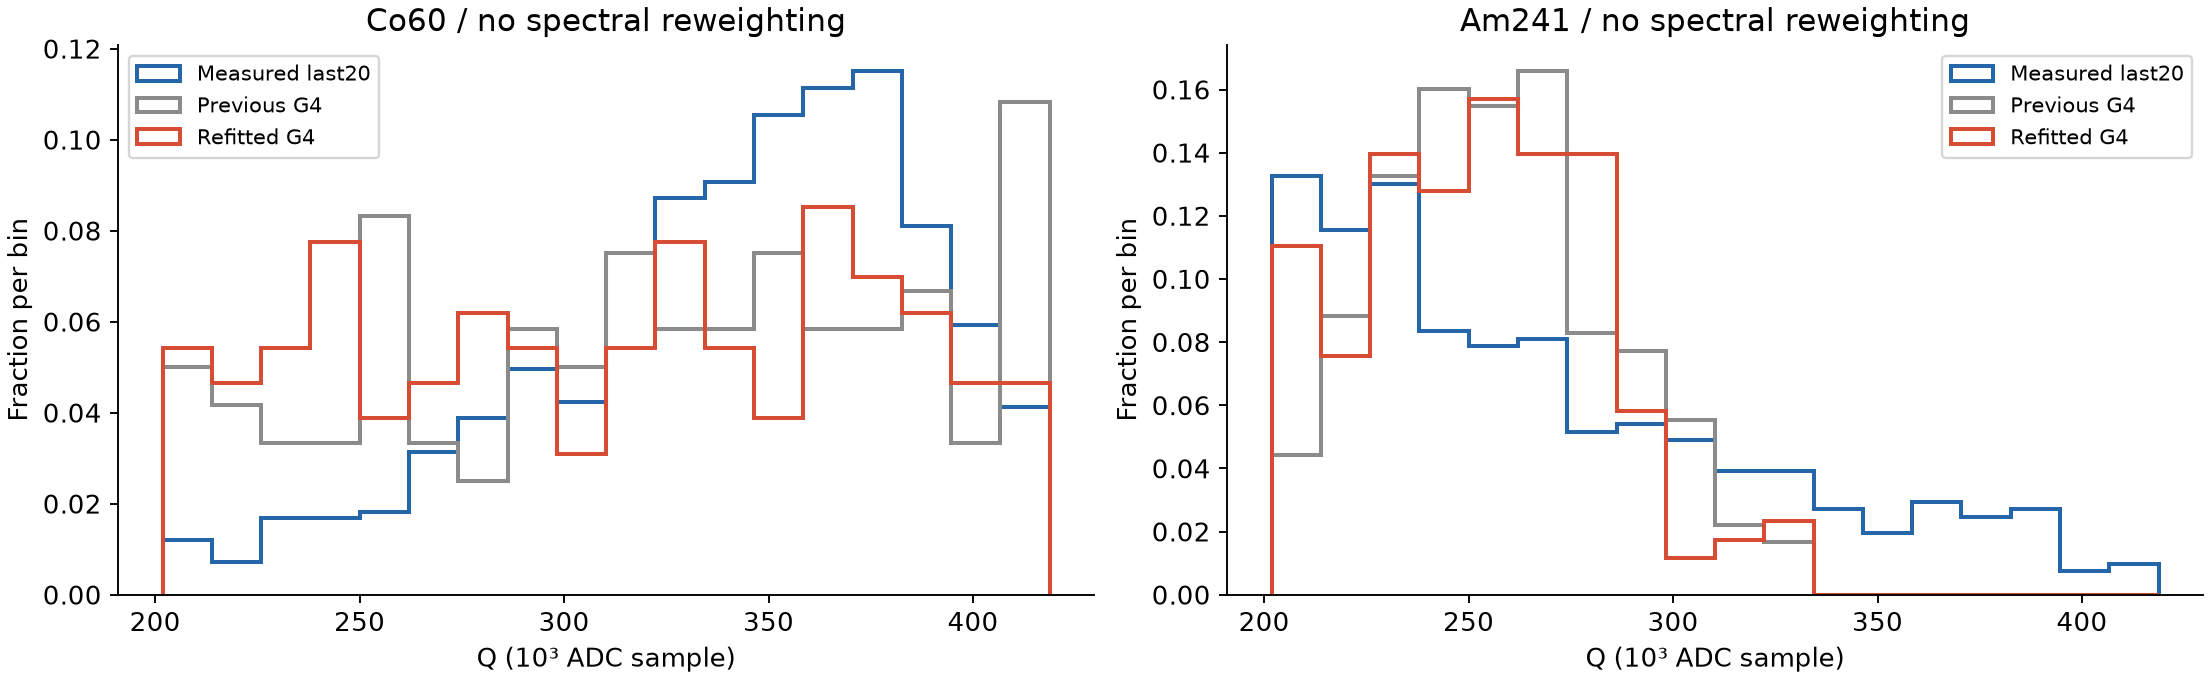

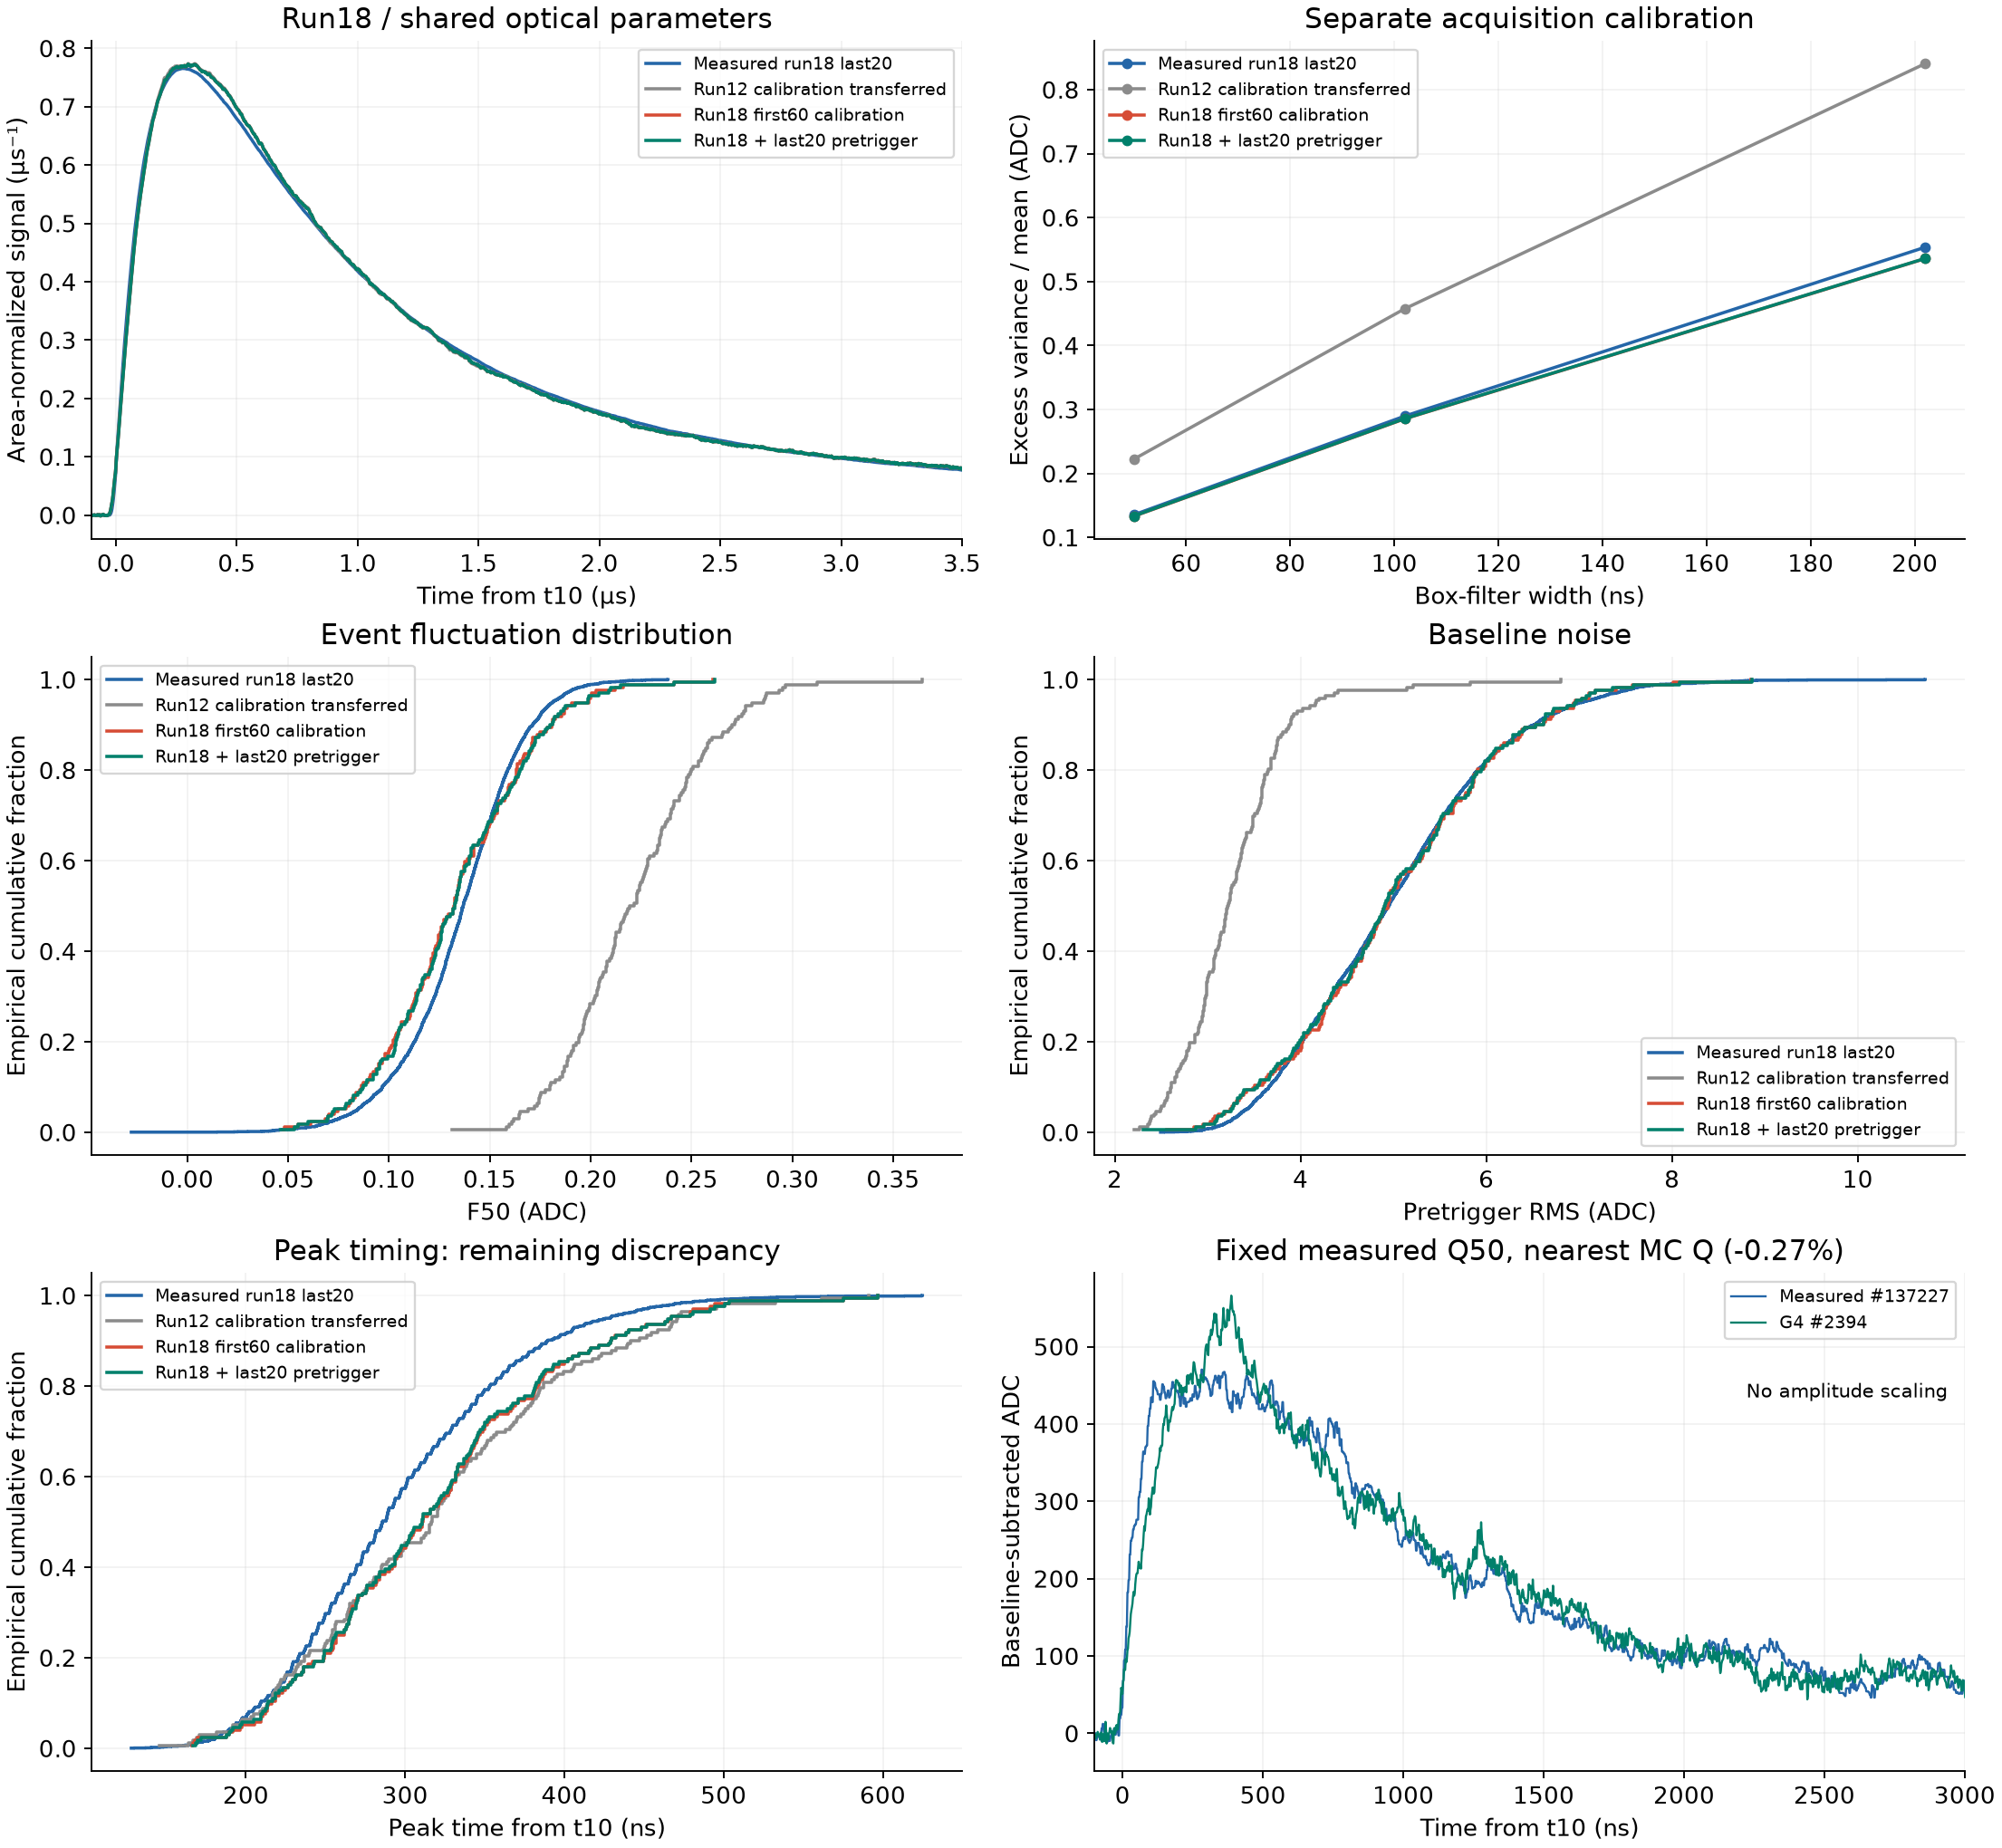

In [6]:
if (NEW / 'final_summary.json').exists():
    result = read(NEW / 'final_summary.json')
    display(Markdown(result['notebook_summary_markdown']))
    for relative in result.get('figures', []):
        display(Image(filename=str(PROJECT / relative)))
else:
    print('完整 Geant4 验证尚未完成，不预填拟合成功结论。')

## 6. 复现与来源

上一阶段：`simulation/results/signal_fluctuations_20261028/record.json`。
本轮数值：`simulation/results/waveform_refit_20261029/`。
笔记生成器：`jupyter/codex_0001_build_notebook.py`，使用现有 Jupyter Python 环境执行。
耗时输运在独立命令中执行；重新运行本笔记只读取保存的数值与图，不自动覆盖冻结模拟。
本轮不修改原始 BIN，也不修改共享文献库。

本轮修改仍在 `simulation/include/`、`simulation/src/` 所组织的 Geant4 工程内执行。
`ReadoutNoise.cc` 增加前触发状态混合、方差分散及相关性；`SignalDependentNoise.cc` 对全零信号跳过无效卷积。
原生完整模拟与重放均调用这些 C++ 模块。Python 负责参数搜索与统计，不替代核衰变、光学输运或 SiPM 雪崩。
最终构建的 5 个 CTest 目标、2 个原生/重放集成测试通过；测试包含逐元素 ADC 一致性、光子与雪崩保留、
状态混合的矩、异常参数、关闭/零信号退化。日志和源码快照存入本轮 `record.json` 对应归档。

当前配置：
- [run 3 / Co](../simulation/configs/csi_tl_run3_waveform_20261029.json)
- [run 12 / Am](../simulation/configs/csi_tl_run12_waveform_20261029.json)
- [run 18 / Am 单独采集校准](../simulation/configs/csi_tl_run18_waveform_20261029.json)

同名前缀的 `_last20_pretrigger.json` 使用后段前触发区校准，不能与前段预测结果混写。
上述配置分别与已验证配置逐字节相同。需要重新产生完整模拟时，在项目根目录使用**新的输出目录**：

```bash
./simulation/build/csi_sources simulation/configs/csi_tl_run3_waveform_20261029.json \
  Co60 4000 291029503 simulation/results/reproduce_20261029_co60/events.root
./simulation/build/csi_sources simulation/configs/csi_tl_run12_waveform_20261029.json \
  Am241 24000 291029512 simulation/results/reproduce_20261029_am241/events.root
python3 simulation/validate.py simulation/results/reproduce_20261029_co60/events.root \
  simulation/results/reproduce_20261029_am241/events.root
```

数值与审计入口：
- [最终参数训练记录](../simulation/results/waveform_refit_20261029/final_parameters/fit.json)
- [新种子完整模拟验证](../simulation/results/waveform_refit_20261029/independent/analysis/validation.json)
- [run 18 单独校准检查](../simulation/results/waveform_refit_20261029/run18/validation.json)
- [各阶段起伏与形状数值 CSV](../simulation/results/waveform_refit_20261029/waveform_validation.csv)
- [特征中位数、条件区间及 KS 数值 CSV](../simulation/results/waveform_refit_20261029/feature_validation.csv)
- [本阶段源码、输入和输出哈希记录](../simulation/results/waveform_refit_20261029/record.json)

没有自动提交或推送 GitHub；本次交付是本地代码、可运行配置、冻结结果与已执行 notebook。